# poor_unoriented: exploratory data analysis

**Source.** RRUFF project, downloaded from
<https://www.rruff.net/zipped_data_files/raman/> on **2026-09-28**. The archive is
`poor_unoriented.zip` (33 MB, 1639 `.txt` files, 81 MB extracted), one of the Raman
subsets RRUFF publishes. The upstream copy in that directory carries a last-modified
date of 2026-06-23, so the archive has not moved since it was fetched.

The RRUFF project itself is described in Lafuente B, Downs R T, Yang H, Stone N (2015),
*The power of databases: the RRUFF project*, in Highlights in Mineralogical
Crystallography, T Armbruster and R M Danisi (eds), Berlin, De Gruyter, pp 1-30.

**Where this notebook sits.** It is the first step of a re-run of the CNN mineral
classifier in `src/cnn`. The earlier run was trained before experiment tracking existed
and used run names that were not descriptive, so nothing about it can be replayed from a
record. This notebook establishes what the dataset actually contains before anything is
trained on it, and turns up one finding that changes how the data has to be split.

**What is loaded.** Every `*.txt` in the dataset directory. The files are RRUFF
two-column exports: `##KEY=value` header lines, then `wavenumber, intensity` pairs,
terminated by `##END=`. This is the same flat-directory layout that
`src.data.loader.load_CNN_data` reads through `ramanspy.datasets.rruff`.

## What `poor_unoriented` means

RRUFF publishes its Raman spectra split on two independent axes, and the archive name
names one cell of that grid.

**The quality axis:** `excellent`, `fair`, `poor`, `unrated`. This is RRUFF's own rating
of the spectrum, not of the mineral. The published archives are
`excellent_oriented.zip`, `excellent_unoriented.zip`, `fair_oriented.zip`,
`fair_unoriented.zip`, **`poor_unoriented.zip`**, `unrated_oriented.zip`,
`unrated_unoriented.zip`, plus `LR-Raman.zip` for the low-resolution collection.

**The orientation axis:** `oriented` or `unoriented`, and it is a statement about the
measurement geometry:

- **Oriented.** The crystal is mounted on a pin in a known crystallographic orientation,
  with a fiducial mark recorded. RRUFF then records which way the laser polarisation sat
  relative to that mark, at discrete angles (0 deg, 45 deg, 90 deg counter-clockwise, or
  "depolarized"). Band intensities in these spectra therefore carry polarisation and
  mode-symmetry information.
- **Unoriented.** The laser meets the sample at an undefined angle relative to the
  crystal axes. No orientation or polarisation metadata is recorded. Relative band
  intensities are not controlled, so band *positions* and the overall shape of the
  pattern are what carries the signal, rather than intensity ratios between bands.

So `poor_unoriented` is: **spectra RRUFF rates as its lowest quality tier, measured on
samples whose orientation relative to the laser was not fixed.**

Two consequences worth stating plainly for a classifier:

1. Only unoriented data exists at the poor tier. There is no `poor_oriented.zip`, so this
   particular archive cannot be supplemented with oriented spectra of the same quality;
   anything mixed in comes from a different tier.
2. Unoriented is the *easier* case for a classifier in the sense that the intensities are
   already uncontrolled, which is what a benchtop measurement of an unknown powder looks
   like. Oriented data would introduce a polarisation dependence the model would have to
   learn to ignore.

**A caveat on the word "poor".** RRUFF does not publish the numeric criteria behind the
rating: what signal-to-noise, fluorescence background or peak quality separates `poor`
from `fair` is not stated anywhere indexed. The dataset's own header lines carry no
quality field either, which is checked in the metadata section below: the rating is a
property of which archive a file was shipped in, and nothing in the file itself records
it. This notebook therefore treats "poor quality" as a description of the archive, and
measures the actual spectral properties directly rather than trusting the label.

## 1. Setting up

Imports, the plotting palette, and where the dataset is found. The directory is looked
for in a few known places rather than hard-coded, because the training config, the
archive as downloaded, and this machine's layout do not agree on one path.

In [1]:
from __future__ import annotations

import glob
import os
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline


def find_repo_root(start: Path) -> Path:
    """Walk up from a directory until the file that marks the repository root."""
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"no pyproject.toml in or above {start}")


# The notebook may be run from the repository root or from notebooks/, so the package
# is put on the path from whichever directory is found rather than assumed.
REPO_ROOT = find_repo_root(Path.cwd().resolve())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src import paths

print(f"repository root: {REPO_ROOT}")

repository root: /home/raj/projects/SH_Project


In [2]:
# Categorical slots are taken in a fixed order and never cycled. The first four were
# checked with a colour-vision-deficiency validator: worst adjacent pair dE 9.1
# (protan), worst normal-vision pair dE 22.9. The aqua and yellow slots sit below 3:1
# contrast on a white surface, so every chart that uses them carries visible value
# labels as well as colour.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SOFT,
    "axes.titlecolor": INK,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,  # grid behind the marks rather than drawn across them
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "xtick.color": INK_SOFT,
    "ytick.color": INK_SOFT,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.frameon": False,
    "legend.fontsize": 9,
    "text.color": INK,
    "figure.dpi": 110,
})


def save(fig, name):
    """Write a figure into the repository's outputs directory and return its path."""
    target = paths.output_path(name)
    fig.savefig(target, bbox_inches="tight", facecolor=SURFACE)
    return target

In [3]:
# The training config points at ~/Code/Data_SH/poor_unoriented, the archive extracts to
# whatever directory it was unzipped in, and the environment variable lets either be
# overridden without editing this notebook.
CANDIDATES = [
    os.environ.get("POOR_UNORIENTED_DIR"),
    Path.home() / "poor_unoriented",
    Path.home() / "Desktop" / "poor_unoriented",
    Path.home() / "Code" / "Data_SH" / "poor_unoriented",
]

DATASET = next(
    (Path(p).expanduser() for p in CANDIDATES if p and Path(p).expanduser().is_dir()),
    None,
)
if DATASET is None:
    raise FileNotFoundError(
        "No dataset directory found. Set POOR_UNORIENTED_DIR, or unzip "
        "poor_unoriented.zip, then add its directory to CANDIDATES."
    )

# Training globs this exact pattern, so building the index from the same call keeps the
# row order identical to the order the model sees.
FILES = [Path(p) for p in glob.glob(f"{DATASET}/*.txt")]
print(f"dataset: {DATASET}")
print(f"files:   {len(FILES)}")

dataset: /home/raj/Desktop/poor_unoriented
files:   1639


## 2. Reading the files

Every file has the same shape: header lines starting `##`, a blank line, then the numeric
block. The parser below keeps the header as a dictionary and the two columns as arrays,
and records the spectral grid of each file so the grids can be compared later.

Reading as `latin-1` matches what `ramanspy` does when it opens these files, and skipping
lines that are not two numbers keeps a stray heading from raising.

In [4]:
HEADER_LINE = re.compile(r"^##([^=]+)=(.*)$")


def parse_rruff(path):
    """Read one RRUFF export into its header dictionary and its two columns.

    Returns:
        tuple[dict, np.ndarray, np.ndarray]: The header, the wavenumber column in cm-1,
        and the intensity column in whatever units RRUFF exported.
    """
    header, shift, intensity = {}, [], []
    with open(path, encoding="latin-1") as handle:
        for line in handle:
            line = line.strip()
            if not line:
                continue
            if line.startswith("##"):
                match = HEADER_LINE.match(line)
                if match is None:
                    continue
                key, value = match.group(1).strip(), match.group(2).strip()
                if key == "END":
                    break
                header[key] = value
                continue
            # A data line is exactly two numbers, so anything else is passed over.
            fields = line.replace(",", " ").split()
            if len(fields) != 2:
                continue
            try:
                shift.append(float(fields[0]))
                intensity.append(float(fields[1]))
            except ValueError:
                continue
    return header, np.asarray(shift), np.asarray(intensity)


parsed = {}
rows = []
for path in FILES:
    header, shift, intensity = parse_rruff(path)
    parsed[path] = (shift, intensity)
    steps = np.diff(shift) if shift.size > 1 else np.array([np.nan])
    rows.append(
        {
            "path": path,
            "file": path.name,
            "mineral": header.get("NAMES", ""),
            "rruff_id": header.get("RRUFFID", ""),
            "wavelength": header.get("RAMAN WAVELENGTH", ""),
            "kind": "RAW" if "RAW" in header.get("FILETYPE", "") else "Processed",
            "status": header.get("STATUS", ""),
            "locality": header.get("LOCALITY", ""),
            "chemistry": header.get("IDEAL CHEMISTRY", ""),
            "cell": header.get("CELL PARAMETERS", ""),
            "measured_chemistry": header.get("MEASURED CHEMISTRY", ""),
            "n_points": int(shift.size),
            "shift_min": float(shift.min()),
            "shift_max": float(shift.max()),
            "step": float(np.median(steps)),
            "intensity_min": float(intensity.min()),
            "intensity_max": float(intensity.max()),
            "n_negative": int((intensity < 0).sum()),
            "n_zero": int((intensity == 0).sum()),
        }
    )

index = pd.DataFrame(rows)
# One physical measurement, exported up to twice: raw and/or processed. This is the key
# a leak-free split has to group on, since holding out a file does not hold out the
# measurement.
index["sample"] = index["mineral"] + "|" + index["rruff_id"] + "|" + index["wavelength"].astype(str)
print(f"parsed {len(index)} files, {index['n_points'].sum():,} points in total")

parsed 1639 files, 3,851,232 points in total


In [5]:
print(f"columns: {list(index.columns)}")
print(f"memory:  {index.memory_usage(deep=True).sum() / 1e6:.1f} MB")
index[["file", "mineral", "rruff_id", "wavelength", "kind",
       "n_points", "shift_min", "shift_max", "step"]].head()

columns: ['path', 'file', 'mineral', 'rruff_id', 'wavelength', 'kind', 'status', 'locality', 'chemistry', 'cell', 'measured_chemistry', 'n_points', 'shift_min', 'shift_max', 'step', 'intensity_min', 'intensity_max', 'n_negative', 'n_zero', 'sample']
memory:  1.8 MB


,file,mineral,rruff_id,wavelength,kind,n_points,shift_min,shift_max,step
0,Silver__R070463__Raman__532______Raman_Data_RA...,Silver,R070463,532,RAW,2417,137.62030,1302.415,0.4821
1,Cerite-(CeCa)__R130614__Raman__780______Raman_...,Cerite-(CeCa),R130614,780,RAW,2478,88.06445,1282.268,0.4821
2,Fluorapatite__R050340__Raman__780______Raman_D...,Fluorapatite,R050340,780,RAW,2460,99.27307,1284.798,0.4821
3,Insizwaite__R070743__Raman__532______Raman_Dat...,Insizwaite,R070743,532,RAW,2310,165.92840,1279.135,0.4821
4,Stephanite__R050143_d__Raman__785______Raman_D...,Stephanite,R050143,785,Processed,2350,140.33000,1272.823,0.4820


## 3. What the archive contains

Three questions: how the files divide between raw and processed, which excitation
wavelengths are present, and how many distinct minerals there are.

In [6]:
by_kind = index["kind"].value_counts().reindex(["Processed", "RAW"])
by_wavelength = index["wavelength"].value_counts().sort_index()

print(f"distinct minerals:      {index['mineral'].nunique()}")
print(f"distinct RRUFF samples: {index['rruff_id'].nunique()}")
print()
print("by export type")
print(by_kind.to_string())
print()
print("by excitation wavelength (nm)")
print(by_wavelength.to_string())
print()
print("export type against wavelength")
print(pd.crosstab(index["kind"], index["wavelength"]).to_string())

distinct minerals:      533
distinct RRUFF samples: 671

by export type
kind
Processed    810
RAW          829

by excitation wavelength (nm)
wavelength
514     21
532    575
780    670
785    373

export type against wavelength
wavelength  514  532  780  785
kind                          
Processed    11  286  330  183
RAW          10  289  340  190


/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_inventory.png


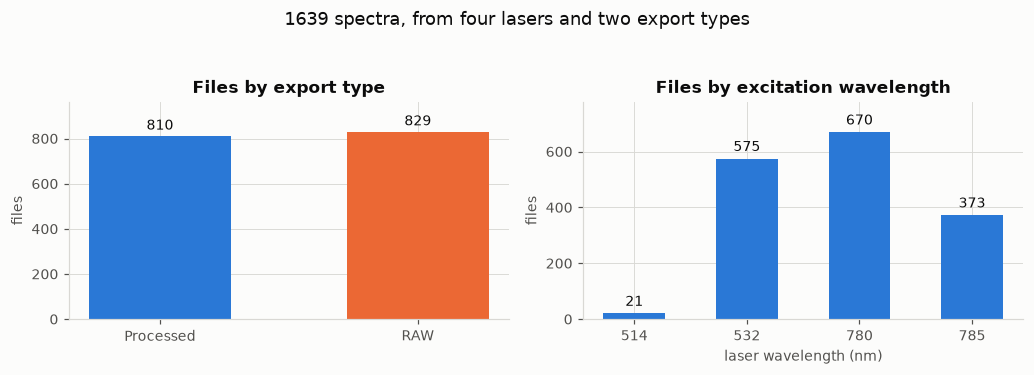

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))

ax = axes[0]
bars = ax.bar(by_kind.index, by_kind.values, color=[BLUE, ORANGE], width=0.55)
for bar, value in zip(bars, by_kind.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 15, f"{value}",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Files by export type")
ax.set_ylabel("files")
ax.set_ylim(0, by_kind.max() * 1.16)

ax = axes[1]
bars = ax.bar(by_wavelength.index, by_wavelength.values, color=BLUE, width=0.55)
for bar, value in zip(bars, by_wavelength.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 15, f"{value}",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title("Files by excitation wavelength")
ax.set_xlabel("laser wavelength (nm)")
ax.set_ylabel("files")
ax.set_ylim(0, by_wavelength.max() * 1.16)

fig.suptitle("1639 spectra, from four lasers and two export types", y=1.05, fontsize=12)
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_inventory.png"))
plt.show()

## 4. Header metadata, and a caveat about the labels

The header lines are where the mineral name and the identification status live. Two
things matter for a classifier: whether the fields are complete, and how much of the
labelling RRUFF itself considers settled.

In [8]:
metadata_fields = ["locality", "chemistry", "cell", "status", "measured_chemistry"]
completeness = pd.DataFrame(
    {
        "present": [int((index[field] != "").sum()) for field in metadata_fields],
        "missing": [int((index[field] == "").sum()) for field in metadata_fields],
    },
    index=metadata_fields,
)
completeness["present_pct"] = (100 * completeness["present"] / len(index)).round(1)
completeness

,present,missing,present_pct
locality,1639,0,100.0
chemistry,1616,23,98.6
cell,1153,486,70.3
status,1639,0,100.0
measured_chemistry,670,969,40.9


In [9]:
def is_unsettled(status):
    """Whether a status wording means the mineral name is not a settled identification.

    RRUFF uses two such wordings: "not yet confirmed", and the bare "Unconfirmed".
    """
    lowered = status.lower()
    return "not yet confirmed" in lowered or lowered.startswith("unconfirmed")


# The mineral name is the label, so how firmly RRUFF established it matters.
unsettled = index["status"].map(is_unsettled)
# Identified by Raman alone, which is the task the classifier is being asked to do.
raman_only = index["status"].str.contains("determined only by Raman", case=False)

print(f"labels RRUFF records as unsettled: {int(unsettled.sum())} "
      f"({100 * unsettled.mean():.1f}%)")
print(f"identifications resting on Raman alone: {int(raman_only.sum())}")
print()
for status, count in index["status"].value_counts().items():
    print(f"{count:5d} {'*' if is_unsettled(status) else ' '} {status}")
print()
print("* the mineral name is a best identification, not a confirmed one")

labels RRUFF records as unsettled: 400 (24.4%)
identifications resting on Raman alone: 11

  398 * The identification of this mineral is not yet confirmed
  298   The identification of this mineral has been confirmed by X-ray diffraction and chemical analysis
  297   The identification of this mineral is confirmed by single-crystal X-ray diffraction and chemical analysis
  251   The identification of this mineral has been confirmed by single-crystal X-ray diffraction
  165   The identification of this mineral has been confirmed only by single crystal X-ray diffraction
  100   The identification of this mineral has been confirmed by X-ray diffraction
   61   The identification of this mineral has been confirmed only by chemical analysis
   27   The identification of this mineral has been confirmed only by X-ray diffraction
   27   The identification of this mineral has been made only by X-ray diffraction
   11   The identification of this mineral has been determined only by Raman spectr

/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_status.png


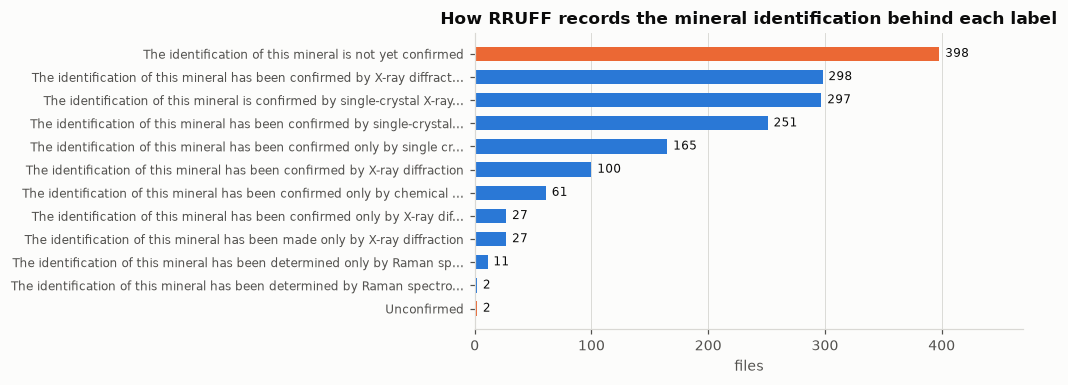

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
status_counts = index["status"].value_counts()
labels = [s if len(s) <= 74 else s[:71] + "..." for s in status_counts.index]
# Orange marks a label RRUFF does not consider settled, blue one it does.
colours = [ORANGE if is_unsettled(s) else BLUE for s in status_counts.index]

bars = ax.barh(range(len(status_counts)), status_counts.values, color=colours, height=0.62)
ax.set_yticks(range(len(status_counts)), labels, fontsize=8)
ax.invert_yaxis()
for bar, value in zip(bars, status_counts.values):
    ax.text(value + 5, bar.get_y() + bar.get_height() / 2, f"{value}",
            va="center", fontsize=8, color=INK)
ax.set_xlabel("files")
ax.set_title("How RRUFF records the mineral identification behind each label")
ax.set_xlim(0, status_counts.max() * 1.18)
ax.grid(axis="y", visible=False)
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_status.png"))
plt.show()

The orange bars are the concern. 400 files, roughly a quarter of the archive, carry a
mineral name RRUFF does not consider settled: the label is a best identification, not a
confirmed one. A model trained on them learns to reproduce an identification the source
database declines to stand behind.

Worth noting too that 11 spectra are identified *by Raman spectroscopy alone*, which is
precisely the thing the classifier is being asked to do. Whatever those contribute, they
are not independent evidence for it.

Neither is a reason to discard the archive: it is the largest single pool of real
measurements at hand. It is a reason to keep the status alongside the label, so accuracy
can be reported on the confirmed subset separately. That string survives parsing into the
`status` column, so it is available to the training config for exactly that purpose.

## 5. The wavenumber grid

RRUFF exports are not resampled to a common axis, so the files disagree about how many
points they hold and over what range. This decides whether the dataset can be fed to a
fixed-input network unmodified, and it is where the training config's `x_min` and `x_max`
come from.

In [11]:
grid_summary = index.groupby("kind").agg(
    files=("n_points", "size"),
    points_min=("n_points", "min"),
    points_median=("n_points", "median"),
    points_max=("n_points", "max"),
    distinct_lengths=("n_points", "nunique"),
    lowest_start=("shift_min", "min"),
    highest_start=("shift_min", "max"),
    lowest_end=("shift_max", "min"),
    highest_end=("shift_max", "max"),
)
grid_summary["distinct_steps"] = index.groupby("kind")["step"].nunique()
print(grid_summary.to_string())
print()
print("grid spacing across the whole archive (cm-1):")
print(index["step"].round(4).value_counts().head(8).to_string())

           files  points_min  points_median  points_max  distinct_lengths  lowest_start  highest_start  lowest_end  highest_end  distinct_steps
kind                                                                                                                                           
Processed    810         837         2356.0        2526               322        52.866       313.3343    1028.435     3456.942              14
RAW          829         837         2416.0        2539               282        26.288       267.1008    1032.104     4242.675              12

grid spacing across the whole archive (cm-1):
step
0.4821    1535
0.4820      78
1.2800       5
1.2750       3
1.9285       3
1.0000       2
1.2810       2
1.2910       2


/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_grid.png


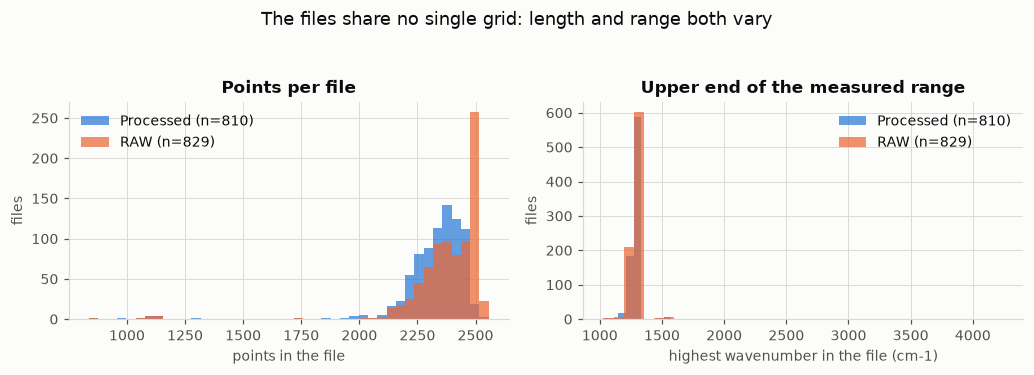

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.2))

ax = axes[0]
bins = np.arange(index["n_points"].min(), index["n_points"].max() + 40, 40)
for kind, colour in (("Processed", BLUE), ("RAW", ORANGE)):
    subset = index.loc[index["kind"] == kind, "n_points"]
    ax.hist(subset, bins=bins, color=colour, alpha=0.72, label=f"{kind} (n={len(subset)})")
ax.set_title("Points per file")
ax.set_xlabel("points in the file")
ax.set_ylabel("files")
ax.legend()

ax = axes[1]
for kind, colour in (("Processed", BLUE), ("RAW", ORANGE)):
    subset = index.loc[index["kind"] == kind, "shift_max"]
    ax.hist(subset, bins=40, color=colour, alpha=0.72, label=f"{kind} (n={len(subset)})")
ax.set_title("Upper end of the measured range")
ax.set_xlabel("highest wavenumber in the file (cm-1)")
ax.set_ylabel("files")
ax.legend()

fig.suptitle("The files share no single grid: length and range both vary", y=1.05, fontsize=12)
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_grid.png"))
plt.show()

### Where the training window comes from

`TrainConfig` puts every spectrum on one axis with
`standardise_data(spectra, input_size=2000, x_min=313.3, x_max=1028.4)`, interpolating
onto a fixed grid and zero-filling outside each spectrum's own range. Those two numbers
are not arbitrary: the check below shows they are the widest window every file in the
archive covers, which is the only choice that avoids throwing measured data away.

In [13]:
from src.config import TrainConfig

window = (index["shift_min"].max(), index["shift_max"].min())
print(f"widest window every one of the {len(index)} files covers: [{window[0]:.2f}, {window[1]:.2f}] cm-1")
print(f"TrainConfig window:                                     [{TrainConfig.x_min}, {TrainConfig.x_max}] cm-1")

covers = (index["shift_min"] <= TrainConfig.x_min) & (index["shift_max"] >= TrainConfig.x_max)
short = index.loc[~covers, ["file", "kind", "shift_min", "shift_max"]].copy()
short["short_by_lo"] = (TrainConfig.x_min - short["shift_min"]).round(3)
short["short_by_hi"] = (TrainConfig.x_max - short["shift_max"]).round(3)

print()
print(f"files covering the config window completely: {int(covers.sum())}/{len(index)}")
print("files that do not, and by how much:")
print(short.to_string(index=False))

step = index["step"].mode().iloc[0]
native = np.arange(window[0], window[1], step).size
print()
print(f"points in that window on the archive's usual {step:.4f} cm-1 grid: {native}")
print(f"input_size={TrainConfig.input_size} resamples the window onto {TrainConfig.input_size} points, "
      f"a factor {TrainConfig.input_size / native:.2f}x")

widest window every one of the 1639 files covers: [313.33, 1028.43] cm-1
TrainConfig window:                                     [313.3, 1028.4] cm-1

files covering the config window completely: 1638/1639
files that do not, and by how much:
                                                                                       file      kind  shift_min  shift_max  short_by_lo  short_by_hi
Anthoinite__R070025__Raman__780______Raman_Data_Processed__031d595d775f4f22d35b011c4b5b.txt Processed   313.3343   1274.675       -0.034     -246.275

points in that window on the archive's usual 0.4821 cm-1 grid: 1484
input_size=2000 resamples the window onto 2000 points, a factor 1.35x


Two readings of that. The window is confirmed to be the archive's own intersection, so the
config is not discarding data: a single file falls short, by 0.03 cm-1 on its low end,
which is an interpolation edge effect rather than a lost measurement. And `input_size=2000`
is a mild *upsampling* of a window that natively holds about 1484 points, so the network's
input is not losing resolution; it is interpolating between measured points. That is worth
revisiting in the retrain (1484 would be the honest input size), but it is not a defect.

## 6. Raw against processed

The archive ships each measurement twice wherever both exist: the raw export, and one with
baseline and cosmic-ray handling applied. They are the same physical measurement, which
turns out to matter a great deal for how the data is split.

In [14]:
paired = index.pivot_table(index="sample", columns="kind", values="file", aggfunc="count").fillna(0).astype(int)
has_raw, has_proc = paired.get("RAW", 0) > 0, paired.get("Processed", 0) > 0

print(pd.Series({
    "measurements (mineral + RRUFF id + wavelength)": len(paired),
    "exported as both RAW and Processed": int((has_raw & has_proc).sum()),
    "RAW only": int((has_raw & ~has_proc).sum()),
    "Processed only": int((~has_raw & has_proc).sum()),
}).to_string())
print()
print("measurements exported more than once on the same side:")
multiple = paired[(paired > 1).any(axis=1)]
print(multiple.to_string() if len(multiple) else "  (none)")

measurements (mineral + RRUFF id + wavelength)    887
exported as both RAW and Processed                747
RAW only                                           80
Processed only                                     60

measurements exported more than once on the same side:
kind                    Processed  RAW
sample                                
Stephanite|R050143|532          3    2
Stephanite|R050143|785          2    2


/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_raw_vs_processed.png


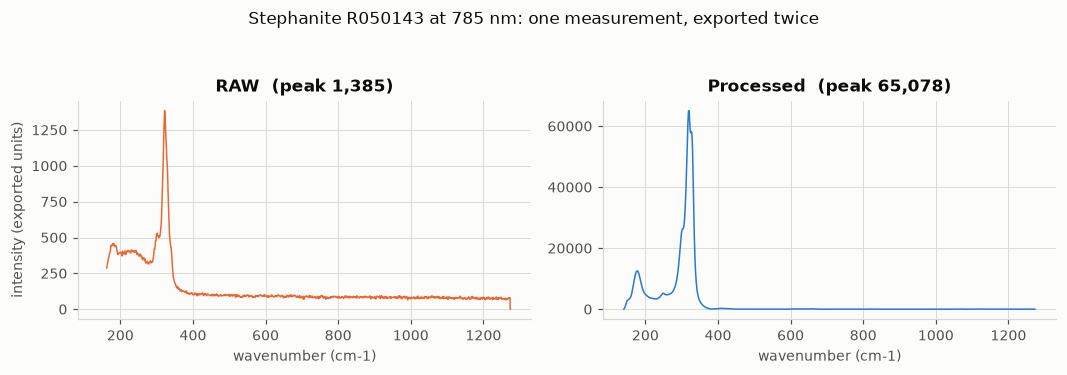

In [15]:
# One pair, drawn together, to show what the processing does and does not change.
shared = index[index["kind"] == "Processed"]["sample"]
shared = shared[shared.isin(index.loc[index["kind"] == "RAW", "sample"])]
example = index[(index["sample"] == shared.iloc[0]) & (index["kind"] == "Processed")].iloc[0]
twin = index[(index["sample"] == example["sample"]) & (index["kind"] == "RAW")].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.2), sharex=True)
for ax, row, colour in ((axes[0], twin, ORANGE), (axes[1], example, BLUE)):
    shift, intensity = parsed[row["path"]]
    ax.plot(shift, intensity, color=colour, linewidth=1.0)
    ax.set_title(f"{row['kind']}  (peak {intensity.max():,.0f})")
    ax.set_xlabel("wavenumber (cm-1)")
axes[0].set_ylabel("intensity (exported units)")
fig.suptitle(f"{example['mineral']} {example['rruff_id']} at {example['wavelength']} nm: "
             "one measurement, exported twice", y=1.05, fontsize=11)
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_raw_vs_processed.png"))
plt.show()

In [16]:
print(index.groupby("kind")["intensity_max"].agg(["min", "median", "max"]).to_string())
print()
print("files holding negative intensities, which the processing clips:")
print(index.groupby("kind")["n_negative"].agg(
    files_with_negatives=lambda s: int((s > 0).sum()),
    total_negative_points="sum",
).to_string())
print()
print("zero-valued points, from baseline flattening:")
print(index.groupby("kind")["n_zero"].sum().to_string())

                min      median        max
kind                                      
Processed  0.730118   299.50165  3322287.0
RAW        0.934997  3239.18100  3584477.0

files holding negative intensities, which the processing clips:
           files_with_negatives  total_negative_points
kind                                                  
Processed                    33                    452
RAW                          51                  15656

zero-valued points, from baseline flattening:
kind
Processed    1323
RAW           166


The raw export keeps absolute detector counts and the processed export has had a baseline
removed, so the two are not on one scale: across the archive the median raw peak is about
3,200 counts against about 300 for the processed export. The pair drawn above inverts even
that, with a processed peak twenty times the raw one, and that inversion is the point. The
two exports are not a rescaling of one another in either direction, so their intensities
cannot be compared in absolute terms at all.

That is why `standardise_data` divides every spectrum by its own peak before the model sees
it. Mixing the two exports in one training set without that step would teach the model the
export type rather than the mineral.

## 7. Class balance

The label is the mineral name, so this is a 533-way problem with a very uneven number of
spectra per class.

In [17]:
per_mineral = index.groupby("mineral").size().sort_values(ascending=False)

print(pd.Series({
    "distinct minerals (classes)": len(per_mineral),
    "spectra per mineral: min": per_mineral.min(),
    "median": per_mineral.median(),
    "mean": round(per_mineral.mean(), 2),
    "max": per_mineral.max(),
    "classes with a single spectrum": int((per_mineral == 1).sum()),
    "classes with exactly two spectra": int((per_mineral == 2).sum()),
    "classes with five or more": int((per_mineral >= 5).sum()),
}).to_string())
print()
print("largest classes:")
print(per_mineral.head(12).to_string())

distinct minerals (classes)         533.00
spectra per mineral: min              1.00
median                                2.00
mean                                  3.08
max                                  14.00
classes with a single spectrum       40.00
classes with exactly two spectra    275.00
classes with five or more            55.00

largest classes:
mineral
Fluorapatite            14
Spinel                  13
Stephanite              13
Chalcocite              12
Djurleite               12
Corundum                11
Cylindrite              10
Beryl                   10
Fluorcalciomicrolite    10
Fluorite                10
Senandorite             10
Allanite-(Ce)            9


/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_balance.png


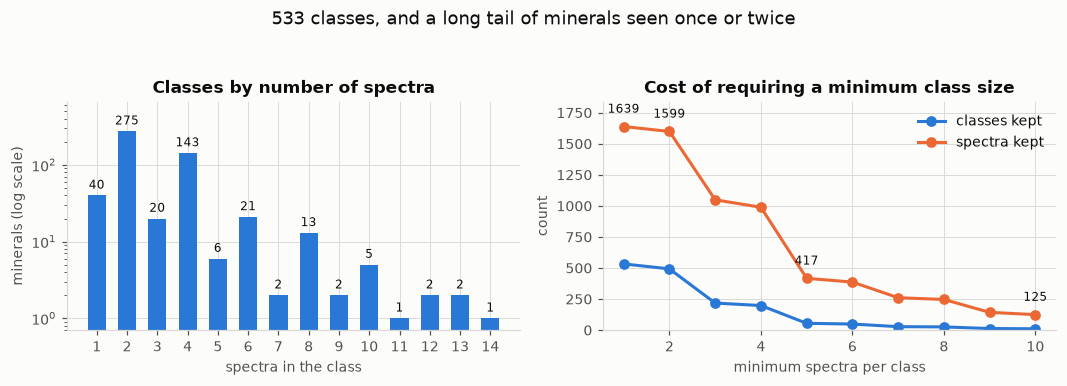

In [18]:
counts = per_mineral.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.3))

ax = axes[0]
bars = ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.6)
for bar, value in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, value * 1.12, f"{value}",
            ha="center", va="bottom", fontsize=8, color=INK)
ax.set_yscale("log")
ax.set_ylim(0.7, counts.max() * 2.4)
ax.set_title("Classes by number of spectra")
ax.set_xlabel("spectra in the class")
ax.set_ylabel("minerals (log scale)")

# What a minimum class size would cost, and buy, in classes and spectra.
ax = axes[1]
thresholds = np.arange(1, 11)
kept_classes = np.array([int((per_mineral >= t).sum()) for t in thresholds])
kept_spectra = np.array([int(per_mineral[per_mineral >= t].sum()) for t in thresholds])
ax.plot(thresholds, kept_classes, color=BLUE, linewidth=2, marker="o", markersize=6,
        label="classes kept")
ax.plot(thresholds, kept_spectra, color=ORANGE, linewidth=2, marker="o", markersize=6,
        label="spectra kept")
for x, y in zip(thresholds, kept_spectra):
    if x in (1, 2, 5, 10):
        ax.annotate(f"{y}", (x, y), textcoords="offset points", xytext=(0, 9),
                    ha="center", fontsize=8, color=INK)
ax.set_title("Cost of requiring a minimum class size")
ax.set_xlabel("minimum spectra per class")
ax.set_ylabel("count")
ax.set_ylim(0, len(index) * 1.12)
ax.legend()

fig.suptitle("533 classes, and a long tail of minerals seen once or twice", y=1.05, fontsize=12)
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_balance.png"))
plt.show()

The tail is the defining feature. 315 of the 533 classes hold two spectra or fewer, and 275
hold exactly two, which means a one-spectrum-per-class hold-out leaves a single training
example for each of them.

That is not a reason to drop classes, but it does mean two things for the retrain: a
per-class metric is more honest than an overall accuracy on a 533-way problem this skewed,
and the augmentation settings (`n_shift`, `n_noise`, and the linear combinations of spectra
within a class) are doing most of the work for the tail.

## 8. The split leaks, and this is the finding that matters

`leave_one_out_split` holds out one spectrum per class, chosen by the run's seed, and
trains on the rest. That is the split the training script uses today, and the accuracy it
reports is measured on those held-out spectra.

Because each measurement is present up to twice, as a raw export and a processed one,
holding out one *file* does not hold out the *measurement*. The twin is still in the
training set.

This section reproduces the split exactly as training builds it: the same
`src.config.PROJECT_SEED`, the same file order, and the same function. The labels are then
checked against the ones the real loader produces, so the reproduction is verifiable
rather than asserted.

In [19]:
from src.config import PROJECT_SEED
from src.cnn.cnn_preprocessing import leave_one_out_split

# Training reads its labels from the ramanspy metadata over the same glob order, so
# building them the same way here is what makes this an exact reproduction.
labels = index["mineral"].str.split(",").str[0].str.strip().to_numpy()
samples = index["sample"].to_numpy()

# Cross-check against the loader training actually calls.
from src.data.loader import load_CNN_data

spectra, metadata = load_CNN_data(str(DATASET))
loader_labels = np.array([m["##NAMES"].split(",")[0].strip() for m in metadata])
print(f"loader returns {len(spectra)} spectra; index holds {len(index)}")
print(f"labels agree with the loader: {bool((loader_labels == labels).all())}")

rng = np.random.default_rng(PROJECT_SEED)
train_idx, test_idx = leave_one_out_split(labels, rng)

train_samples = set(samples[train_idx])
test_samples = samples[test_idx]
leaked = np.array([s in train_samples for s in test_samples])

print()
print(f"seed:          {PROJECT_SEED}")
print(f"train spectra: {len(train_idx)}")
print(f"held out:      {len(test_idx)}")
print()
print(f"held-out spectra whose twin export is in training: {int(leaked.sum())} of {len(test_idx)} "
      f"({100 * leaked.mean():.1f}%)")
print(f"held-out spectra with a clean split:               {int((~leaked).sum())}")
print()
train_ids = set(index.loc[train_idx, "rruff_id"])
test_ids = index.loc[test_idx, "rruff_id"]
print(f"held-out spectra whose RRUFF sample also appears in training: "
      f"{int(test_ids.isin(train_ids).sum())} of {len(test_ids)}")

loader returns 1639 spectra; index holds 1639
labels agree with the loader: True

seed:          20260924
train spectra: 1146
held out:      493

held-out spectra whose twin export is in training: 466 of 493 (94.5%)
held-out spectra with a clean split:               27

held-out spectra whose RRUFF sample also appears in training: 486 of 493


/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_leakage.png


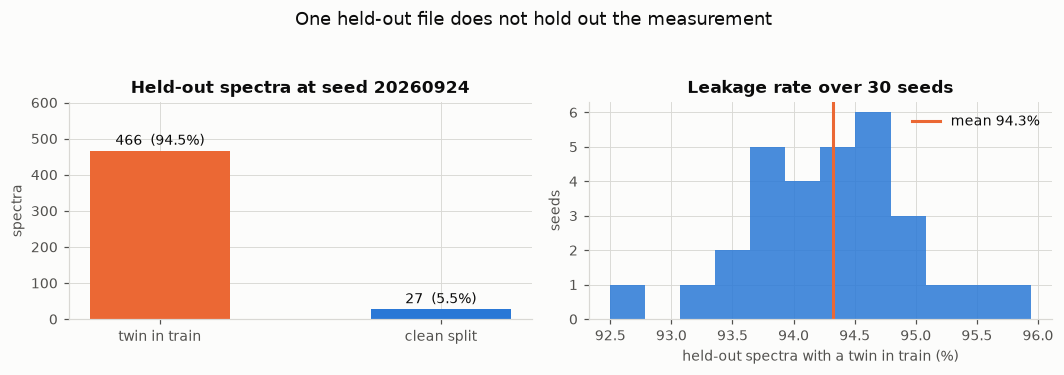

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.2))

ax = axes[0]
values = [int(leaked.sum()), int((~leaked).sum())]
bars = ax.bar(["twin in train", "clean split"], values, color=[ORANGE, BLUE], width=0.5)
for bar, value in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 8,
            f"{value}  ({100 * value / len(test_idx):.1f}%)",
            ha="center", va="bottom", fontsize=9, color=INK)
ax.set_title(f"Held-out spectra at seed {PROJECT_SEED}")
ax.set_ylabel("spectra")
ax.set_ylim(0, len(test_idx) * 1.22)

# The same count over many seeds, to show it is a property of the data and not the seed.
ax = axes[1]
rates = []
for seed in range(30):
    other_train, other_test = leave_one_out_split(labels, np.random.default_rng(seed))
    other_samples = set(samples[other_train])
    rates.append(np.mean([s in other_samples for s in samples[other_test]]))
rates = np.array(rates) * 100
ax.hist(rates, bins=12, color=BLUE, alpha=0.85)
ax.axvline(rates.mean(), color=ORANGE, linewidth=2, label=f"mean {rates.mean():.1f}%")
ax.set_title("Leakage rate over 30 seeds")
ax.set_xlabel("held-out spectra with a twin in train (%)")
ax.set_ylabel("seeds")
ax.legend()

fig.suptitle("One held-out file does not hold out the measurement", y=1.05, fontsize=12)
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_leakage.png"))
plt.show()

This is the main result of the notebook, and it accounts for the 90.7% test accuracy the
previous run reported. Most held-out spectra have their own measurement's twin sitting in
the training set, so the model is largely being asked to recognise a spectrum it has
already seen in the other export format. The number that split produces is not a measure of
mineral identification.

The same leakage runs through the wavelengths as well: 212 RRUFF samples were measured with
more than one laser, and those exports are the same crystal under the same identification.
Whatever split the retrain uses has to key on the measurement, which is `mineral` +
`rruff_id`, and not on the file. Grouping by that key and holding out whole measurements
closes both routes at once. The index already carries it as the `sample` column, exactly
for that.

Reporting an honest number means evaluating on a split this notebook does not build, which
is the next piece of work rather than this one.

## 9. What the spectra look like

Two views to sanity-check the archive before trusting the numbers above: individual
processed spectra at each laser, and the median shape at each laser once everything is on
one axis.

/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_examples.png


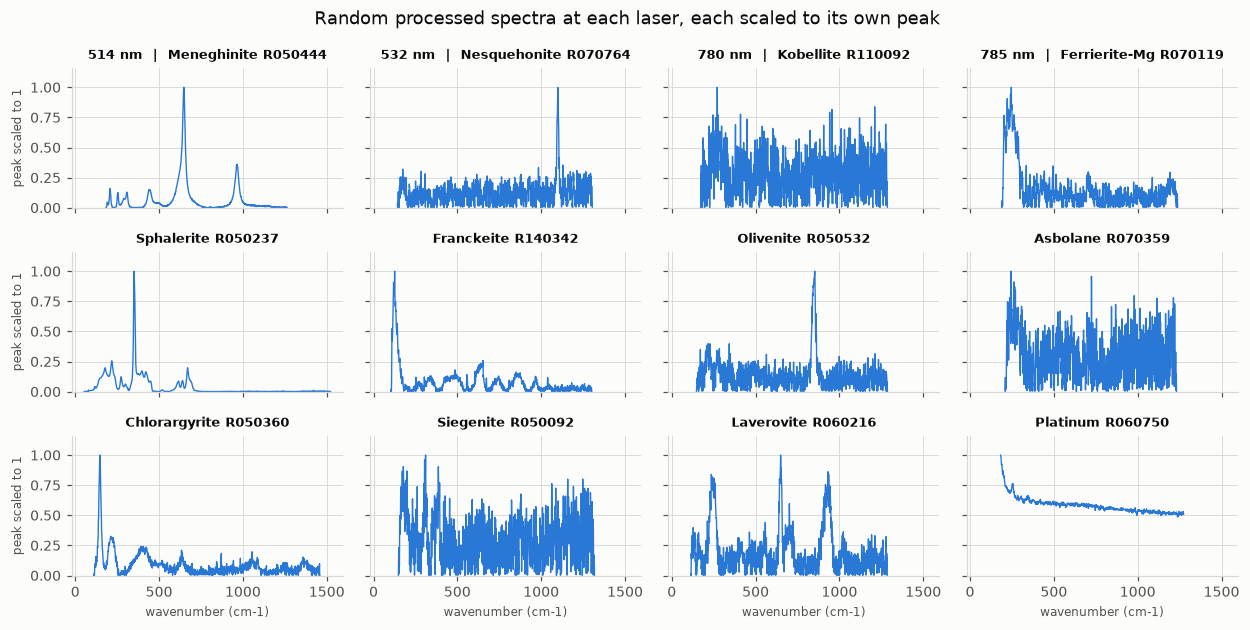

In [21]:
processed = index[index["kind"] == "Processed"]
chosen = pd.concat(
    [group.sample(min(3, len(group)), random_state=0) for _, group in processed.groupby("wavelength")]
)
wavelengths = sorted(chosen["wavelength"].unique())

# One spectrum per panel rather than three overlaid: these traces are noisy by nature, and
# a title carrying the mineral says what a legend would without covering the data.
rows = 3
fig, axes = plt.subplots(rows, len(wavelengths), figsize=(11.5, 5.8), sharex=True, sharey=True)
for column, wavelength in enumerate(wavelengths):
    group = chosen[chosen["wavelength"] == wavelength].reset_index(drop=True)
    for row in range(rows):
        ax = axes[row, column]
        if row >= len(group):
            ax.axis("off")
            continue
        entry = group.iloc[row]
        shift, intensity = parsed[entry["path"]]
        ax.plot(shift, intensity / (intensity.max() or 1.0), color=BLUE, linewidth=0.9)
        mineral = f"{entry['mineral']} {entry['rruff_id']}"
        ax.set_title(f"{wavelength} nm  |  {mineral}" if row == 0 else mineral, fontsize=8.5)
        if column == 0:
            ax.set_ylabel("peak scaled to 1", fontsize=8)
        if row == rows - 1:
            ax.set_xlabel("wavenumber (cm-1)", fontsize=8)
        ax.set_ylim(0, 1.16)

fig.suptitle("Random processed spectra at each laser, each scaled to its own peak",
             y=0.98, fontsize=12)
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_examples.png"))
plt.show()

/home/raj/projects/SH_Project/outputs/poor_unoriented_eda_median_spectra.png


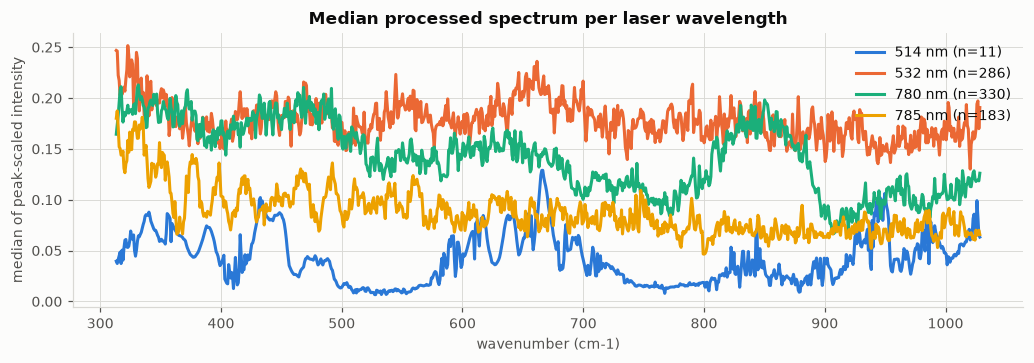

In [22]:
# Processed spectra interpolated onto one axis, so their shapes can be compared.
axis = np.linspace(TrainConfig.x_min, TrainConfig.x_max, 900)
colours = {"514": BLUE, "532": ORANGE, "780": AQUA, "785": YELLOW}

fig, ax = plt.subplots(figsize=(9.5, 3.4))
for wavelength, colour in colours.items():
    subset = processed[processed["wavelength"] == wavelength]
    if subset.empty:
        continue
    curves = []
    for _, row in subset.iterrows():
        shift, intensity = parsed[row["path"]]
        peak = intensity.max() or 1.0
        curves.append(np.interp(axis, shift, intensity / peak, left=0, right=0))
    ax.plot(axis, np.median(np.asarray(curves), axis=0), color=colour, linewidth=2,
            label=f"{wavelength} nm (n={len(curves)})")

ax.set_xlabel("wavenumber (cm-1)")
ax.set_ylabel("median of peak-scaled intensity")
ax.set_title("Median processed spectrum per laser wavelength")
ax.legend()
fig.tight_layout()
print(save(fig, "poor_unoriented_eda_median_spectra.png"))
plt.show()

## 10. Findings

**What the archive is.** 1639 RRUFF Raman exports, 533 mineral classes, four laser
wavelengths (780 nm is most common at 670 files, then 532 at 575, 785 at 373, 514 at 21).
The 1639 files cover 887 measurements, and 747 of those appear as both a raw and a
processed export, which leaves 140 files as the only export of their measurement.

**The name.** `poor_unoriented` is RRUFF's lowest quality tier crossed with an unoriented
measurement geometry. The laser met the sample at an undefined angle to the crystal axes,
so band positions carry the signal rather than orientation-dependent intensity ratios. No
oriented data exists at this tier.

**The window is sound.** `TrainConfig`'s `[313.3, 1028.4]` cm-1 is the widest window all
1639 files cover, so training discards no measured data. `input_size=2000` upsamples a
window that natively holds about 1484 points on the archive's usual 0.4821 cm-1 grid:
worth revisiting, not wrong.

**Two things to settle before the retrain.**

1. **The split leaks.** The one-file-per-class hold-out leaves 466 of 493 held-out spectra
   (94.5%) with their own measurement's twin in the training set, and the rate is stable
   across seeds. That is very likely where the previous run's 90.7% came from. Split on
   `mineral` + `rruff_id`, not on the file.
2. **A quarter of the labels are not settled.** 400 of 1639 spectra carry a mineral name
   RRUFF records as unconfirmed, and 11 are identified by Raman alone. Keep the status
   field, and report accuracy on the confirmed subset separately.

**What carries forward.** The `sample` column is the grouping key for a clean split; the
`status` column is the filter for an honest accuracy figure; the `kind` column is the
decision about whether the model trains on raw exports, processed ones or both. Those two
exports are on different intensity scales, and `standardise_data` rescales per spectrum, so
mixing them is defensible, but it should be a deliberate choice recorded in the run config
rather than an accident of what was lying in the directory.